
# 03 因子投资：方法与实践 · 核心笔记

> **这本书要解决的问题**：股票收益能不能被少数几个“因子”解释？怎么用数据检验一个因子是真的、还是挖出来的？A 股常用哪些因子、它们为什么可能有效？一个人做量化，怎么把书里的方法用起来而不被“因子动物园”淹没？

## 本章导读

这是石川、刘洋溢、连祥斌《因子投资：方法与实践》（2020）的**零基础核心笔记**。原书体系很大，这里只留一条主线，把“公式—方法—A 股因子—实践”串起来：

1. 一个统一公式：$E[R]=\beta\lambda+\alpha$，把因子、暴露、溢价、定价误差放在同一行；
2. 三组概念：因子 / 多因子模型 / 异象；定价因子 / 异象因子；截面 / 时序；
3. 一套方法：组合排序、Rank IC、Fama–MacBeth 回归、Newey–West、GMM、GRS 检验、因子正交化；
4. 一份 A 股因子清单：市场、规模、价值、动量、盈利、投资、换手，以及 CAPM/FF3/FF5/CH3 等模型；
5. 一些实践问题：Barra 风险模型、组合优化、Smart Beta、因子拥挤、发表后衰减，以及对一人量化的用法。

全文代码都用**合成数据**（500 只股票 × 120 个月，教学示例），不连接任何行情源；数字是为了讲清方法，不代表真实市场。

### 学习目标

- 能解释 $E[R]=\beta\lambda+\alpha$ 每一项的含义，并手算一个三因子例子。
- 能分清因子、多因子模型、异象，以及定价因子与异象因子。
- 能用十分组排序和 Rank IC 做单因子初筛，并读懂单调性和多空 t 值。
- 能用 Fama–MacBeth 两步法估计因子溢价，并用 Newey–West 修正 t 值。
- 能说出 GMM、GRS 检验、因子正交化各自解决什么问题。
- 能列出 A 股 7 个主流因子的度量、方向与经济逻辑，知道 CAPM/FF3/FF5/CH3 的差别。
- 能解释“因子动物园”和 t>3 的由来，以及发表后衰减、因子拥挤的含义。
- 能为一人量化设计一个“先验证、后组合、再看成本”的最小工作流。

### 先修

零基础即可：会加减乘除、知道“平均”和“相关性”的大意；能读一点 Python。概率、回归的细节会在用到时用大白话解释。

---

### 环境准备



In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：因子研究员、量化选股、FOF/资管、Smart Beta 产品设计、风险模型团队。
- **输入**：股票收益面板、财务与估值数据、交易/流动性数据、因子定义。
- **输出**：因子溢价估计、因子有效性报告、多因子模型、组合权重与风险归因。
- **在流程的哪一步**：从“有一个想法”到“能定价、能组合、能解释”的中枢环节。
- **失败模式**：把相关当因果、只看单因子、不做多重检验、忽略成本与容量、把回测当未来。
- **最小工作流**：定义因子 → 排序/IC 初筛 → Fama–MacBeth 控制其他因子 → 看 t 值与稳健性 → 组合与成本 → 样本外与拥挤监控。

---

## 1. 统一公式：$E[R]=\beta\lambda+\alpha$

### 1.1 公式怎么读

$$\underbrace{E[R_i]}_{\text{股票 }i\text{ 的预期收益}}=\underbrace{\beta_i'\lambda}_{\text{暴露}\times\text{因子溢价}}+\underbrace{\alpha_i}_{\text{模型没解释的部分}}.$$

- $R_i$：股票 $i$ 的收益率（通常按月）；
- $\beta_i$：这只股票在各类因子上的**暴露**（敏感度），比如市场 beta、规模暴露、价值暴露；
- $\lambda$：每个因子的**溢价**（承担一单位暴露的补偿），是“市场给的价格”；
- $\alpha$：**定价误差**。模型定价正确时 $\alpha=0$；$\alpha>0$ 说明这只股票比模型预测的更赚。

一句话：**收益 = 暴露 × 价格 + 残差**。因子投资做的事，就是找出“价格”（$\lambda$）和“暴露”（$\beta$），再看残差（$\alpha$）还有没有系统性的部分。

### 1.2 手算一个例子

假设市场溢价 $\lambda_{\text{mkt}}=6\%$、规模溢价 $\lambda_{\text{size}}=3\%$、价值溢价 $\lambda_{\text{val}}=4\%$。某股票的市场 beta 为 1.1、规模暴露 0.5（小市值方向）、价值暴露 0.4，则

$$\beta'\lambda=1.1\times6\%+0.5\times3\%+0.4\times4\%=6.6\%+1.5\%+1.6\%=9.7\%.$$

如果它实际实现了 12.5%，那么 $\alpha=12.5\%-9.7\%=2.8\%$：模型解释了一部分，还剩 2.8% 没解释。这个 2.8% 可能是真本事（遗漏因子、信息优势），也可能只是运气或数据问题——**这正是后面所有检验要回答的事**。

### 1.3 因子、多因子模型、异象

| 概念 | 一句话 | 例子 |
|---|---|---|
| 因子 | 一组股票共同暴露的、能解释收益差异的特征或收益来源 | 市场、规模、价值 |
| 多因子模型 | 用若干因子的暴露给资产定价的方程 | CAPM、FF3、FF5、CH3 |
| 异象 | 某个特征在历史上能预测收益、但尚未被模型解释的现象 | 低波动、应计、换手 |

三者关系：**异象是“现象”，因子是“解释变量”，多因子模型是“定价框架”**。一个异象要变成因子，通常要满足：有经济逻辑、长期稳健、不能被已有因子解释、可投资。

### 1.4 定价因子 vs 异象因子

- **定价因子**：被主流模型承认、有风险补偿或行为解释，能解释一大片资产。例如市场、规模、价值、盈利、投资。
- **异象因子**：单独排序显著，但可能只是某个定价因子的“影子”，或数据挖掘的结果。

判断要点：把异象因子和已有因子放在同一个截面回归里，如果它的溢价变得不显著，说明它大概率只是已有因子的代理。**“单独显著”不等于“独立有效”。**

### 1.5 截面 vs 时序

| 视角 | 看什么 | 常见工具 |
|---|---|---|
| 时序 | 一个因子组合的收益序列（多空组合、因子收益） | 均值、t 检验、Newey–West、最大回撤 |
| 截面 | 同一个月份，不同股票的收益差异 | 排序分组、Rank IC、截面回归 |

两者缺一不可：时序告诉你“这个因子长期有没有溢价”，截面告诉你“这个月的收益是被哪些暴露解释的”。Fama–MacBeth 就是把两者接起来的桥。

--- 

## 2. 方法论：从排序到回归

### 2.1 投资组合排序：单/双/三重

**单排序**：按一个因子给股票排序，分 5 组或 10 组，看每组平均收益是否单调。

- 做多最高组、做空最低组，得到**多空组合**；
- 多空收益的均值就是因子溢价的粗略估计，t 值看它是否稳定。

**双排序**：控制第二个变量。例如先按市值分组，再在每个市值组内按价值排序，看价值效应是否还在。**三重排序**再加一个维度（比如先市值、再行业、再价值），用来排除“其实是行业效应”。

排序的优点是直观、少假设；缺点是分组是人选的、会丢掉组内信息、对极端值敏感。

### 2.2 Rank IC 与单调性

**IC**（信息系数）是因子值与下期收益的截面相关系数。用秩（排名）算相关就是 **Rank IC**，它对极端值更稳健：

$$\text{IC}_t=\text{corr}\left(\text{rank}(f_{i,t}),\ \text{rank}(R_{i,t+1})\right).$$

- IC 均值越大，因子预测力越强；
- **ICIR** = IC 均值 / IC 标准差，衡量“预测力稳不稳定”；
- 单调性看 10 组的平均收益是否一档一档往上（或往下）。

### 2.3 代码：先造一份合成面板

下面用 500 只股票、120 个月、3 个因子造数据。真实收益只由市场、规模、价值三个因子决定；另外造一个“换手”变量，它和价值高度相关、但**不进入真实收益**——后面用它演示“单因子显著、多因子不显著”。



In [2]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(7135)
N, T = 500, 120
premia = np.array([0.006, 0.004, 0.006])          # 市场、规模、价值：教学示例
factor_vol = np.array([0.045, 0.020, 0.025])
phi = 0.25
burn = 50
factor_ret = np.zeros((T + burn, 3))
shock = rng.normal(0.0, factor_vol, size=(T + burn, 3))
for t in range(1, T + burn):
    factor_ret[t] = premia + phi * (factor_ret[t - 1] - premia) + shock[t]
factor_ret = factor_ret[burn:]

mkt = rng.normal(1.0, 0.25, N)
size = rng.normal(0.0, 1.0, N)
value = rng.normal(0.0, 1.0, N)
turnover = 0.6 * value + rng.normal(0.0, 0.8, N)   # 换手与价值相关，但不进入真实收益
exposures = np.column_stack([mkt, size, value])
idio = rng.normal(0.0, 0.02, size=(N, T))
returns = exposures @ factor_ret.T + idio          # 500 × 120

print("股票数", N, "月数", T, "收益矩阵", returns.shape)
print("因子年化均值", np.round(factor_ret.mean(axis=0) * 12, 4),
      "年化波动", np.round(factor_ret.std(axis=0, ddof=1) * np.sqrt(12), 4))
print("暴露相关系数 value/turnover", round(float(np.corrcoef(value, turnover)[0, 1]), 2))


股票数 500 月数 120 收益矩阵 (500, 120)
因子年化均值 [0.0777 0.0692 0.1084] 年化波动 [0.1597 0.0693 0.0943]
暴露相关系数 value/turnover 0.55



**读数**：面板共 500 只股票 × 120 个月；三个因子样本内年化均值分别为 7.77%、6.92%、10.84%，年化波动 15.97%、6.93%、9.43%。价值暴露和换手暴露的相关系数 0.55——**换手在“替价值说话”，但它本身不进真实收益**。记住这一点，第 5 节会用到。

### 2.4 代码：十分组排序与 Rank IC



十分组月均收益(年化) [-0.1029 -0.0319  0.0172  0.0298  0.071   0.0959  0.1357  0.1526  0.1771
  0.2756]
单调性: 最低组<最高组 True
多空组合: 年化 0.3785 波动 0.3265 Sharpe 1.159 t 值 3.67
Rank IC 均值 0.1696 ICIR 0.316 IC t 值 3.46


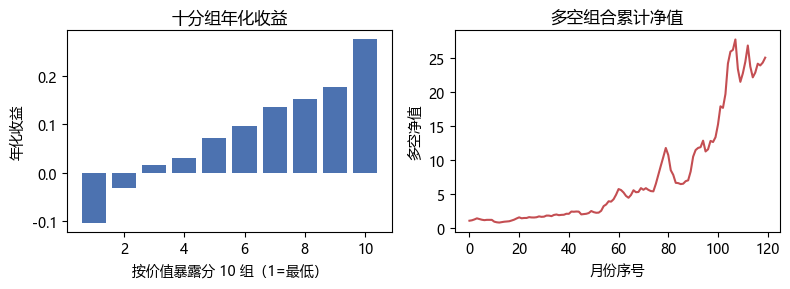

In [3]:

from scipy.stats import spearmanr


def decile_returns(score, ret):
    order = np.argsort(score)
    groups = np.array_split(order, 10)
    return np.array([ret[idx].mean() for idx in groups])


dec = np.array([decile_returns(value, returns[:, t]) for t in range(T)])
ls = dec[:, -1] - dec[:, 0]
print("十分组月均收益(年化)", np.round(dec.mean(axis=0) * 12, 4))
print("单调性: 最低组<最高组", bool(dec[:, 0].mean() < dec[:, -1].mean()))
print("多空组合: 年化", round(float(ls.mean() * 12), 4), "波动",
      round(float(ls.std(ddof=1) * np.sqrt(12)), 4),
      "Sharpe", round(float(ls.mean() / ls.std(ddof=1) * np.sqrt(12)), 3),
      "t 值", round(float(ls.mean() / (ls.std(ddof=1) / np.sqrt(T))), 2))

ic = np.array([spearmanr(value, returns[:, t])[0] for t in range(T)])
print("Rank IC 均值", round(float(ic.mean()), 4), "ICIR",
      round(float(ic.mean() / ic.std(ddof=1)), 3),
      "IC t 值", round(float(ic.mean() / (ic.std(ddof=1) / np.sqrt(T))), 2))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(range(1, 11), dec.mean(axis=0) * 12, color="#4c72b0")
axes[0].set_xlabel("按价值暴露分 10 组（1=最低）")
axes[0].set_ylabel("年化收益")
axes[0].set_title("十分组年化收益")
axes[1].plot(np.cumprod(1 + ls), color="#c44e52")
axes[1].set_xlabel("月份序号")
axes[1].set_ylabel("多空净值")
axes[1].set_title("多空组合累计净值")
plt.tight_layout()
plt.show()



**读数**：10 组年化收益从 −10.29% 一路升到 27.56%，单调性很干净；多空组合年化 37.85%、波动 32.65%、Sharpe 1.159、t 值 3.67。Rank IC 均值 0.1696、ICIR 0.316、IC 的 t 值 3.46。**排序看“形状”，IC 看“每天/每月的方向一致性”，两个都要看。**

### 2.5 Fama–MacBeth 回归与 Newey–West

Fama–MacBeth 两步法：

1. 每个月做一次**截面回归**：$R_{i,t}=\lambda_{0,t}+\beta_i'\lambda_t+\epsilon_{i,t}$，得到当月的溢价估计 $\hat\lambda_t$；
2. 对 $\hat\lambda_t$ 在时间上求平均：$\hat\lambda=\frac1T\sum_t\hat\lambda_t$，再看它离 0 有多远。

标准误要考虑时间序列自相关。**Newey–West** 用“自协方差加权和”修正：

$$\hat\sigma^2_{NW}=\hat\gamma_0+2\sum_{l=1}^{L}\left(1-\frac{l}{L+1}\right)\hat\gamma_l,$$

$L$ 是滞后截断（带宽）。直白地说：相邻月份的溢价估计会“抱团”，NW 把这部分重复信息扣掉，t 值通常更保守。

### 2.6 代码：三因子 Fama–MacBeth 与 NW t 值



In [4]:

def fama_macbeth(y, X):
    N_, T_ = y.shape
    Xc = np.column_stack([np.ones(N_), X])
    lam = np.array([np.linalg.lstsq(Xc, y[:, t], rcond=None)[0] for t in range(T_)])
    return lam


def newey_west_se(x, lags):
    x = np.asarray(x, dtype=float)
    e = x - x.mean()
    T_ = len(x)
    s = e @ e / T_
    for l in range(1, lags + 1):
        w = 1.0 - l / (lags + 1.0)
        s += 2.0 * w * (e[l:] @ e[:-l]) / T_
    return np.sqrt(s / T_)


lags = int(np.floor(4 * (T / 100) ** (2 / 9)))
lam_all = fama_macbeth(returns, exposures)
names = ["市场", "规模", "价值"]
for j, name in enumerate(names):
    lam_j = lam_all[:, j + 1]
    mean_lambda = float(lam_j.mean())
    t_ols = mean_lambda / (lam_j.std(ddof=1) / np.sqrt(T))
    t_nw = mean_lambda / newey_west_se(lam_j, lags)
    print(name, "lambda(月)", round(mean_lambda, 4), "年化", round(mean_lambda * 12, 4),
          "OLS t", round(float(t_ols), 2), "NW t", round(float(t_nw), 2))
print("Newey-West 滞后 L", lags)


市场 lambda(月) 0.0063 年化 0.0762 OLS t 1.51 NW t 1.2
规模 lambda(月) 0.0057 年化 0.0687 OLS t 3.14 NW t 2.79
价值 lambda(月) 0.0092 年化 0.11 OLS t 3.68 NW t 2.95
Newey-West 滞后 L 4



**读数**：市场溢价 0.63%/月（年化 7.62%），t 值 OLS 1.51、NW 1.20，不显著；规模 0.57%/月（年化 6.87%），3.14→2.79；价值 0.92%/月（年化 11.0%），3.68→2.95。**价值因子的 OLS t 值超过 3，但 NW 修正后降到 2.95，刚好跌破“t>3”这条线**——差之毫厘，结论就要更谨慎。本例给因子加了 0.25 的 AR(1)，所以 NW 的修正是有实际效果的。

### 2.7 多因子与正交化：单因子显著，多因子后不显著

把一个“影子因子”和真因子放在同一个截面回归里，会发生什么？下面比较换手在单因子和多因子模型里的表现，再把换手对价值做**正交化**（去掉与价值相关的部分）后重估。

正交化公式（对价值回归取残差）：

$$\text{turnover}^{\perp}=\text{turnover}-\hat{a}-\hat{b}\cdot\text{value},\qquad \hat{b}=\frac{\text{Cov}(\text{turnover},\text{value})}{\text{Var}(\text{value})}.$$

### 2.8 代码：换手因子的“假显著”



In [5]:

lam_turn = fama_macbeth(returns, turnover)
mean_turn = float(lam_turn[:, 1].mean())
t_turn = mean_turn / (lam_turn[:, 1].std(ddof=1) / np.sqrt(T))

lam_multi = fama_macbeth(returns, np.column_stack([value, turnover]))
means = lam_multi[:, 1:].mean(axis=0)
ts = means / (lam_multi[:, 1:].std(axis=0, ddof=1) / np.sqrt(T))
print("单因子(换手): lambda(月)", round(mean_turn, 4), "t", round(float(t_turn), 2))
print("多因子(价值,换手): lambda", np.round(means, 4), "t", np.round(ts, 2))

X0 = np.column_stack([np.ones(N), value])
coef = np.linalg.lstsq(X0, turnover, rcond=None)[0]
turn_orth = turnover - X0 @ coef
lam_orth = fama_macbeth(returns, turn_orth)
print("正交化换手: lambda(月)", round(float(lam_orth[:, 1].mean()), 4),
      "t", round(float(lam_orth[:, 1].mean() / (lam_orth[:, 1].std(ddof=1) / np.sqrt(T))), 2))
print("正交化后与价值相关", round(float(np.corrcoef(turn_orth, value)[0, 1]), 4))


单因子(换手): lambda(月) 0.005 t 3.65
多因子(价值,换手): lambda [0.0089 0.0001] t [3.58 0.99]
正交化换手: lambda(月) 0.0001 t 0.99
正交化后与价值相关 -0.0



**读数**：换手单独看，溢价 0.50%/月、t 值 3.65，很显著；但把价值和换手一起放进截面回归，价值仍有 0.89%/月（t 3.58），换手只剩 0.01%/月（t 0.99）。把换手对价值正交化后，相关系数变成 0，溢价和 t 值依旧接近 0。**换手单因子“显著”，只是价值因子的影子。** 这就是“多因子回归/正交化”最重要的用途：把共享的信息拆开。

### 2.9 GMM、GRS 与模型比较

- **GMM（广义矩估计）**：先写下理论矩条件 $E[g(R_t,\theta)]=0$，再选参数让样本矩尽量接近 0。它不要求正态分布，允许异方差、自相关，还能用“过度识别检验”（J 统计量）检查模型设定。Fama–MacBeth 可以看成 GMM 的一个特例。
- **GRS 检验**：Gibbons–Ross–Shanken 用来检验“一组资产的定价误差是否联合为零”。把 $N$ 个测试资产对 $K$ 个因子做时序回归，得到 alpha 向量 $\hat\alpha$ 和残差协方差 $\hat\Sigma$：

$$F_{GRS}=\frac{T}{N}\cdot\frac{T-N-K}{T-K-1}\cdot
\frac{\hat\alpha'\hat\Sigma^{-1}\hat\alpha}{1+\hat\mu'\hat\Omega^{-1}\hat\mu}
\sim F(N,T-N-K).$$

如果模型定价正确，$F$ 应该小、p 值大；$F$ 大、p 小就拒绝这个模型。**GRS 比较的是“模型整体”，不是单个因子。**

### 2.10 代码：CAPM vs 三因子，GRS 检验与 t>3



CAPM: GRS 3.097 p 0.0017 最大|alpha|年化 0.2031
三因子: GRS 1.364 p 0.2069 最大|alpha|年化 0.0079
试验次数 1 Bonferroni 双侧 5% 门槛 t ≈ 1.96
试验次数 10 Bonferroni 双侧 5% 门槛 t ≈ 2.81
试验次数 100 Bonferroni 双侧 5% 门槛 t ≈ 3.48
试验次数 1000 Bonferroni 双侧 5% 门槛 t ≈ 4.06
t=2.0 单次 p 0.0455 t=3.0 单次 p 0.0027


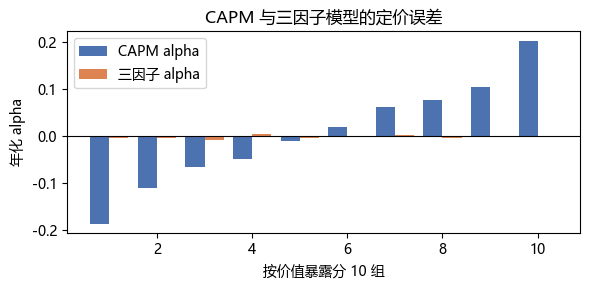

In [6]:

from scipy.stats import f as f_dist
from scipy.stats import norm


def time_series_alpha(port, factors):
    T_, N_ = port.shape
    Xf = np.column_stack([np.ones(T_), factors])
    coef = np.linalg.lstsq(Xf, port, rcond=None)[0]
    resid = port - Xf @ coef
    return coef[0], resid


def grs_stat(port, factors):
    T_, N_ = port.shape
    K_ = factors.shape[1]
    alpha, resid = time_series_alpha(port, factors)
    sigma = resid.T @ resid / T_
    mu = factors.mean(axis=0)
    omega = np.atleast_2d(np.cov(factors, rowvar=False, bias=True))
    num = float(alpha @ np.linalg.inv(sigma) @ alpha)
    den = float(1.0 + mu @ np.linalg.inv(omega) @ mu)
    stat = (T_ / N_) * ((T_ - N_ - K_) / (T_ - K_ - 1.0)) * num / den
    pvalue = 1.0 - f_dist.cdf(stat, N_, T_ - N_ - K_)
    return alpha, stat, pvalue


capm_alpha, capm_grs, capm_p = grs_stat(dec, factor_ret[:, [0]])
ff3_alpha, ff3_grs, ff3_p = grs_stat(dec, factor_ret)
print("CAPM: GRS", round(float(capm_grs), 3), "p", f"{float(capm_p):.4f}",
      "最大|alpha|年化", round(float(np.abs(capm_alpha).max() * 12), 4))
print("三因子: GRS", round(float(ff3_grs), 3), "p", f"{float(ff3_p):.4f}",
      "最大|alpha|年化", round(float(np.abs(ff3_alpha).max() * 12), 4))

for m in [1, 10, 100, 1000]:
    print("试验次数", m, "Bonferroni 双侧 5% 门槛 t ≈", round(float(norm.ppf(1 - 0.05 / (2 * m))), 2))
print("t=2.0 单次 p", round(float(2 * (1 - norm.cdf(2.0))), 4),
      "t=3.0 单次 p", round(float(2 * (1 - norm.cdf(3.0))), 4))

fig, ax = plt.subplots(figsize=(6, 3))
xpos = np.arange(1, 11)
ax.bar(xpos - 0.2, capm_alpha * 12, width=0.4, label="CAPM alpha", color="#4c72b0")
ax.bar(xpos + 0.2, ff3_alpha * 12, width=0.4, label="三因子 alpha", color="#dd8452")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("按价值暴露分 10 组")
ax.set_ylabel("年化 alpha")
ax.set_title("CAPM 与三因子模型的定价误差")
ax.legend()
plt.tight_layout()
plt.show()



**读数**：用 10 个价值分组组合当测试资产，CAPM 的 GRS=3.097、p=0.0017，拒绝“CAPM 能定价”；最大年化 alpha 达 20.31%。加上规模、价值后，三因子 GRS=1.364、p=0.2069，不能拒绝，最大 alpha 只剩 0.79%。**同一个资产集，模型换一下，定价误差从 20% 掉到 1%——这就是“模型比较”的意义。**

再看多重检验：单次 t=2 对应 p≈0.0455，t=3 对应 p≈0.0027。如果试了 10 个因子，Bonferroni 门槛约 2.81；试 100 个约 3.48；试 1000 个约 4.06。**这就是 Harvey–Liu–Zhu 说的“t>3”的由来：因子挖得越多，门槛越高。**

---

## 3. A 股主流因子速查

### 3.1 七个常见因子

| 因子 | 常见度量 | 方向 | 经济逻辑 | 失效/注意 |
|---|---|---|---|---|
| 市场 | 对市场组合的 beta | 高 beta 长期应补偿 | 系统性风险 | 短期 beta 与收益关系不稳定 |
| 规模 | 市值、流通市值 | 小市值溢价 | 流动性/风险补偿、壳价值 | A 股 2017 年后小市值效应明显减弱 |
| 价值 | EP、BP、CFP | 便宜的好 | 均值回归、风险补偿 | 价值陷阱、行业偏差 |
| 动量 | 过去 12 个月（跳过最近 1 月）收益 | 强者恒强 | 反应不足、趋势 | A 股短期反转强，动量较弱 |
| 盈利 | ROE、ROA、毛利率 | 盈利质量高 | 质量溢价 | 盈利操纵、周期波动 |
| 投资 | 资产增速、资本开支 | 低投资更好 | 过度投资、贴现率 | 行业扩张期相反 |
| 换手 | 换手率、异常换手 | 低换手更好 | 投机/流动性溢价 | 与规模、价值高度相关 |

**A 股特色**：小市值和壳价值在注册制、退市制度改革后减弱；短期反转比动量更明显；换手/流动性类因子长期有解释力；涨跌停、停牌、ST 会污染因子值和收益。

### 3.2 多因子模型简史

| 模型 | 因子 | 要点 |
|---|---|---|
| CAPM | 市场 | 一个 beta 解释一切 |
| FF3 | 市场、规模、价值 | 规模用市值，价值用 BP |
| FF5 | 市场、规模、价值、盈利、投资 | 加 RMW、CMA |
| CH3 / CH4 | 市场、规模、价值（EP），CH4 加换手 | 针对 A 股的本土化模型（文献常见做法） |

模型不是越多越好：因子越多，解释力通常越强，但过拟合、共线性、经济含义模糊的风险也越大。**能解释、能投资、能复现，比 R² 高更重要。**

### 3.3 因子动物园与多重检验

学术界已经报告过几百个“能预测收益”的特征，被称为“因子动物园”。问题在于：试的次数越多，纯靠运气也能挖出显著结果。应对办法：

1. 提高显著性门槛（t>3，或按试验次数做 Bonferroni/FDR）；
2. 要求样本外、跨市场、跨时期稳健；
3. 要求经济逻辑和可投资性；
4. 看发表后的收益衰减（文献常见结论：样本外和发表后会明显下降，McLean & Pontiff 2016 估计样本外约降 26%、发表后约降 58%）；
5. 监控因子拥挤：同质资金、相关性上升、估值价差收窄、回撤加深。

---

### 3.4 A 股三个经典异象（书中案例）

原书第 5 章用三个例子说明“异象”长什么样：

| 异象 | 直觉 | 要注意 |
|---|---|---|
| 预期差 | 实际业绩/指引相对市场预期有差，超预期组后续可能跑赢 | 预期数据难拿、公告有滞后，容易被修正 |
| 基本面锚定反转 | 价格短期偏离基本面“锚”，随后向锚回归 | 锚怎么选很主观，反转可能很慢 |
| 特质性波动率 | 低特质波动的股票，风险调整后收益反而更高（IVOL 异象） | 与套利限制/散户偏好有关，学术上争议大 |

这三个不是“买了就赚”的公式，而是“现象 → 找解释 → 控制已有因子 → 看是否独立”的研究素材。

### 3.5 行为金融与机器学习（书第 6 章）

- **行为金融**：人有限理性，存在过度反应/反应不足、情绪、处置效应；同时有套利限制，错误定价不会立刻消失。行为框架用来解释“为什么这个异象可能持续”。
- **机器学习**：能抓非线性和高维交互，但金融信噪比低，极易过拟合；必须配 purged CV、样本外、经济逻辑和多重检验，不能只报测试集准确率。
- **因子动物园**：几百个候选因子中，真正独立、可解释、可投资的很少；先做“减法”，再做“加法”。

## 4. 实践：从模型到组合

### 4.1 Barra 风险模型

Barra 这类**结构化风险模型**把收益拆成：

$$r=Xf+u,$$

$X$ 是风格/行业暴露，$f$ 是因子收益，$u$ 是特质收益。风险则是

$$\Sigma=XFX'+\Delta,$$

$F$ 是因子协方差，$\Delta$ 是特质风险对角阵。它的用途不是“预测收益”，而是**度量风险、做中性化、做组合优化**。商业 Barra 模型的参数是黑箱，一人量化可以自建简化版：行业哑变量 + 几个风格暴露 + 收缩协方差。

### 4.2 组合优化

给定预期收益 $\alpha$ 和风险模型 $\Sigma$，常见形式：

$$\max_w\ w'\alpha-\lambda w'\Sigma w
\quad\text{s.t.}\quad \mathbf{1}'w=1,\ \ |w_i|\le c,\ \ \text{行业/风格中性}.$$

$\lambda$ 是风险厌恶系数；约束决定“能不能买、买多少”。优化器的输出对输入极其敏感：$\alpha$ 估错、$\Sigma$ 估错，权重都会走极端。**先做约束，再谈优化。**

### 4.3 Smart Beta

Smart Beta 是把因子暴露做成指数产品：价值指数、红利指数、低波指数、质量指数等。核心是三件事：**加权方案**（市值/等权/因子打分/风险加权）、**因子定义**、**成本与容量**。对一人量化的启示：如果只是想获得因子暴露，低成本、透明的规则化组合可能比“精细优化”更划算。

### 4.4 对一人量化的用法

1. 先选 2–3 个**低相关、有经济逻辑**的因子，别一上来就 20 个；
2. 用排序 + Rank IC 做初筛，再用 Fama–MacBeth 控制其他因子；
3. 看**扣费后**、样本外、跨时期的 t 值，t>3 更稳；
4. 用风险模型做中性化和组合约束，别让组合被一个因子绑架；
5. 每月监控因子拥挤、相关性、回撤和换手；
6. 把回测当“假设检验”，不是“未来收益承诺”。

---

### 4.5 因子择时、风格归因与风险归因（书第 7 章）

- **因子择时**：按因子估值、因子动量、宏观/情绪调整因子权重。书里态度谨慎：可做，但很容易过拟合；个人投资者优先把“配置”做对，再谈择时。
- **风格归因**：把组合收益拆成市场、规模、价值、动量、质量等风格暴露，先看“赚的是不是因子的钱”。
- **风险归因**：把组合波动/回撤拆成因子风险、行业风险、特质风险；先看风险来自哪里，再谈优化。
- **对一人量化**：先做风险归因和成本归因，再考虑因子择时；归因表比“预测下个月哪个因子好”更可靠。

## 本章小结

### 一张表

| 主题 | 关键公式/做法 | 用途 |
|---|---|---|
| 统一公式 | $E[R]=\beta\lambda+\alpha$ | 把收益拆成暴露和定价误差 |
| 排序 | 十分组、多空组合 | 看单调性、估溢价 |
| Rank IC | 秩相关、ICIR | 衡量预测力与稳定性 |
| Fama–MacBeth | 月度截面回归 + 时间平均 | 估因子溢价 |
| Newey–West | 自协方差加权标准误 | 修正 t 值 |
| 多因子/正交化 | 控制变量、取残差 | 识别“影子因子” |
| GMM | 矩条件 + 加权 | 稳健估计、J 检验 |
| GRS | 联合 alpha 检验 | 比较模型 |
| 多重检验 | t>3、Bonferroni/FDR | 防数据挖掘 |
| 风险模型 | $\Sigma=XFX'+\Delta$ | 组合优化与归因 |

### 八句话

1. 收益 = 暴露 × 因子价格 + 定价误差。
2. 异象是现象，因子是解释，模型是框架。
3. 单独显著不等于独立有效，放进多因子再试一次。
4. 排序看形状，IC 看方向，两者都要看。
5. Fama–MacBeth 把时序和截面接起来。
6. Newey–West 让 t 值对自相关更诚实。
7. 因子挖得越多，显著性门槛越高（t>3）。
8. 回测是假设检验，不是未来承诺。

---

## 本章习题

**1.** 用 $E[R]=\beta\lambda+\alpha$ 计算：市场溢价 6%、规模溢价 3%、价值溢价 4%，某股票 beta=1.2、规模暴露 0.3、价值暴露 0.5，实际收益 11%。求 $\beta'\lambda$ 和 $\alpha$。

**2.** 因子、多因子模型、异象三者有什么区别？举一个 A 股例子说明“异象”和“因子”的关系。

**3.** 为什么单因子排序显著、还不能直接说这个因子有效？多因子回归能检查什么？

**4.** Rank IC 和普通 IC 的区别是什么？ICIR 高说明什么？

**5.** Fama–MacBeth 两步法的两步分别是什么？为什么要用 Newey–West 修正？

**6.** GRS 检验的原假设是什么？CAPM 的 GRS p=0.002、三因子 p=0.21，能说明什么？

**7.** 试了 100 个因子，Bonferroni 双侧 5% 的门槛 t 约是多少？这和非 Bonferroni 的 t=1.96 有什么区别？

**8.** 一个人做量化，拿到一个“年化 20%、t=2.5”的因子，下一步应该做哪三件事？

<details><summary>参考答案</summary>

**1.** $\beta'\lambda=1.2\times6\%+0.3\times3\%+0.5\times4\%=7.2\%+0.9\%+2.0\%=10.1\%$；$\alpha=11\%-10.1\%=0.9\%$。

**2.** 因子是一组股票的共同暴露/收益来源；多因子模型是用因子给资产定价的方程；异象是历史上能预测收益的现象。例如“低换手股票跑赢高换手”是异象；如果它不能被规模、价值解释，并能稳定复现，才可能被当作因子纳入模型。

**3.** 单因子显著可能只是其他因子的代理（例如换手与价值相关）。多因子回归把其他因子同时放进来，看这个因子的溢价是否还显著；正交化则直接把共享部分去掉再检验。

**4.** 普通 IC 用原始值算相关，受极端值影响大；Rank IC 用排名算，更稳健。ICIR = IC 均值/标准差，高说明预测方向稳定、不是靠个别月份。

**5.** 第一步：每个月做截面回归，得到当月的因子溢价 $\lambda_t$；第二步：对 $\lambda_t$ 序列求均值并做 t 检验。月度溢价序列可能有自相关，Newey–West 用自协方差修正标准误，避免 t 值虚高。

**6.** 原假设是“所有测试资产的定价误差（alpha）联合为零”，即模型定价正确。CAPM 的 p=0.002 拒绝 CAPM；三因子 p=0.21 不能拒绝，说明三因子在这个资产集上解释得更好（但仍不能证明它是“真模型”）。

**7.** 试 100 次时 Bonferroni 门槛约 t≈3.48（双侧 5%）；它比 t=1.96 高得多，因为要把“100 次里至少一次碰巧显著”的概率控制住。t=1.96 只适用于只试一次的情形。

**8.** 三件事：① 放进多因子回归/正交化，看是不是已有因子的影子；② 看样本外、扣费后、跨时期的稳健性和 t 值（是否 >3）；③ 检查经济逻辑、容量和拥挤度，再决定是否进入组合。

</details>

---

## 参考资料

- 石川、刘洋溢、连祥斌.《因子投资：方法与实践》. 电子工业出版社, 2020.（本书原书）
- Fama, E. F. & French, K. R. (1993). Common Risk Factors in the Returns on Stocks and Bonds.
- Fama, E. F. & French, K. R. (2015). A Five-Factor Asset Pricing Model.
- Fama, E. F. & MacBeth, J. D. (1973). Risk, Return, and Equilibrium: Empirical Tests.
- Newey, W. K. & West, K. D. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix.
- Gibbons, M. R., Ross, S. A. & Shanken, J. (1989). A Test of the Efficiency of a Given Portfolio.
- Harvey, C. R., Liu, Y. & Zhu, H. (2016). …and the Cross-Section of Expected Returns.
- McLean, R. D. & Pontiff, J. (2016). Does Academic Research Destroy Stock Return Predictability?
- Liu, J., Stambaugh, R. F. & Yuan, Y. (2019). Size and Value in China.
